In [1]:
# Imports and random seed (Task 3-1)

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, losses
from tensorflow.keras.models import Model
from tensorflow.keras.datasets import fashion_mnist

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [2]:
# Load and preprocess Fashion-MNIST for autoencoders (normalize)

from tensorflow.keras.datasets import fashion_mnist

(x_train, _), (x_test, _) = fashion_mnist.load_data()

# normalize all values between 0 and 1 (Lecture 3 style)
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

print("x_train:", x_train.shape, "x_test:", x_test.shape)
print("min/max:", x_train.min(), x_train.max())

x_train: (60000, 28, 28) x_test: (10000, 28, 28)
min/max: 0.0 1.0


In [3]:
# Vanilla Autoencoder model (Flatten → Dense(latent) → Dense(784) → Reshape)

latent_dim = 64  # same idea as Lecture 3 vanilla latent size

class VanillaAutoencoder(Model):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = tf.keras.Sequential([
            layers.Flatten(),
            layers.Dense(latent_dim, activation="relu"),
        ])
        self.decoder = tf.keras.Sequential([
            layers.Dense(784, activation="sigmoid"),
            layers.Reshape((28, 28)),
        ])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

vanilla_ae = VanillaAutoencoder(latent_dim)
vanilla_ae.compile(optimizer="adam", loss=losses.MeanSquaredError())

vanilla_ae.summary()

Model: "vanilla_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Train Vanilla Autoencoder (epochs=10, shuffle=True, validation on test)

history_vanilla = vanilla_ae.fit(
    x_train, x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=1
)

final_train_loss = history_vanilla.history["loss"][-1]
final_val_loss = history_vanilla.history["val_loss"][-1]
print("Final Train Loss:", final_train_loss)
print("Final Val Loss:", final_val_loss)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0532 - val_loss: 0.0286
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0239 - val_loss: 0.0200
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0176 - val_loss: 0.0157
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0146 - val_loss: 0.0137
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0130 - val_loss: 0.0126
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0121 - val_loss: 0.0117
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0114 - val_loss: 0.0112
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0109 - val_loss: 0.0108
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0105 - val_loss: 0.0104
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0102 - val_loss: 0.0101
Final Train Loss: 0.01016504131257534
Final Val Loss: 0.010091078467667103


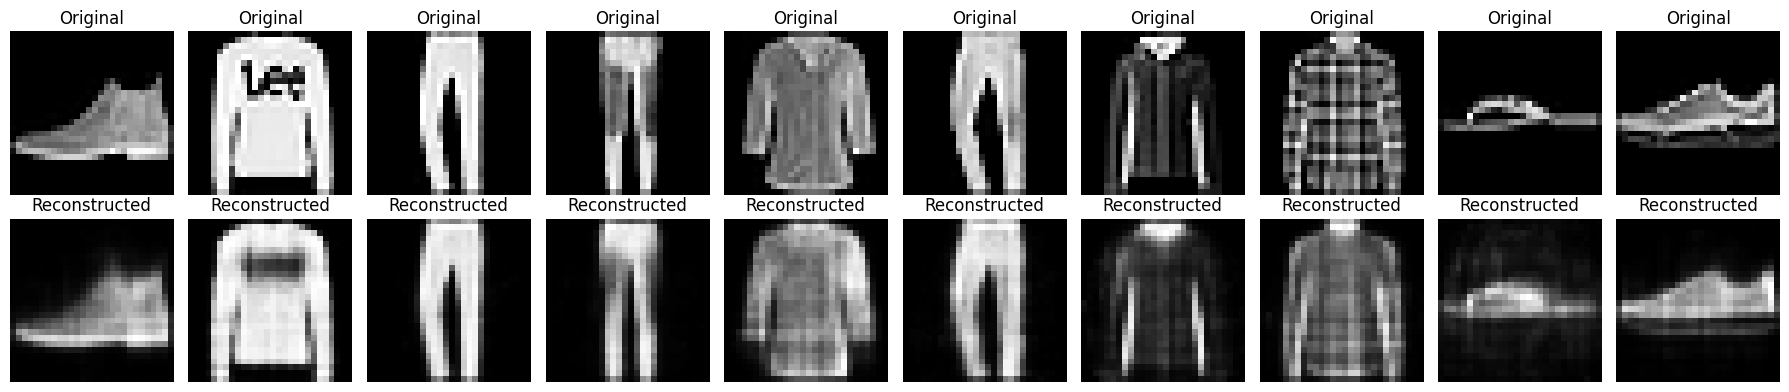

In [5]:
# Visualize Vanilla Autoencoder reconstructions (test samples)

encoded_imgs = vanilla_ae.encoder(x_test)
decoded_imgs = vanilla_ae.decoder(encoded_imgs)

n = 10  # number of test samples to visualize

plt.figure(figsize=(18, 4))
for i in range(n):
    # original images
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # reconstructed images
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i], cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# Deep Autoencoder model (784→512→256→128→64→128→256→512→784)

# flatten for dense AE (Lecture 3 style)
x_train_flat = x_train.reshape((len(x_train), 784))
x_test_flat  = x_test.reshape((len(x_test), 784))

input_img = layers.Input(shape=(784,))

# Encoder
e1 = layers.Dense(512, activation="relu")(input_img)
e2 = layers.Dense(256, activation="relu")(e1)
e3 = layers.Dense(128, activation="relu")(e2)
latent = layers.Dense(64, activation="relu", name="latent")(e3)

# Decoder
d1 = layers.Dense(128, activation="relu")(latent)
d2 = layers.Dense(256, activation="relu")(d1)
d3 = layers.Dense(512, activation="relu")(d2)
output_img = layers.Dense(784, activation="sigmoid")(d3)

deep_ae = tf.keras.Model(input_img, output_img, name="deep_autoencoder")
deep_ae.compile(optimizer="adam", loss="mse")

deep_ae.summary()

Model: "deep_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 784)            │       402,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,149,520 (4.39 MB)

 Trainable params: 1,149,520 (4.39 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Train Deep Autoencoder (epochs=10, batch_size=256)

history_deep = deep_ae.fit(
    x_train_flat, x_train_flat,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_flat, x_test_flat),
    verbose=1
)

final_train_loss_deep = history_deep.history["loss"][-1]
final_val_loss_deep = history_deep.history["val_loss"][-1]
print("Final Train Loss (Deep):", final_train_loss_deep)
print("Final Val Loss (Deep):", final_val_loss_deep)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - loss: 0.0414 - val_loss: 0.0234
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 0.0207 - val_loss: 0.0185
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - loss: 0.0175 - val_loss: 0.0173
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 0.0158 - val_loss: 0.0150
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 0.0145 - val_loss: 0.0141
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 0.0135 - val_loss: 0.0134
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 0.0129 - val_loss: 0.0128
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - loss: 0.0124 - val_loss: 0.0123
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 0.0119 - val_loss: 0.0119
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 0.0116 - val_loss: 0.0118
Final Train Loss (Deep): 0.011555513367056847
Final Val Loss (Deep): 0.011843168176710606


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


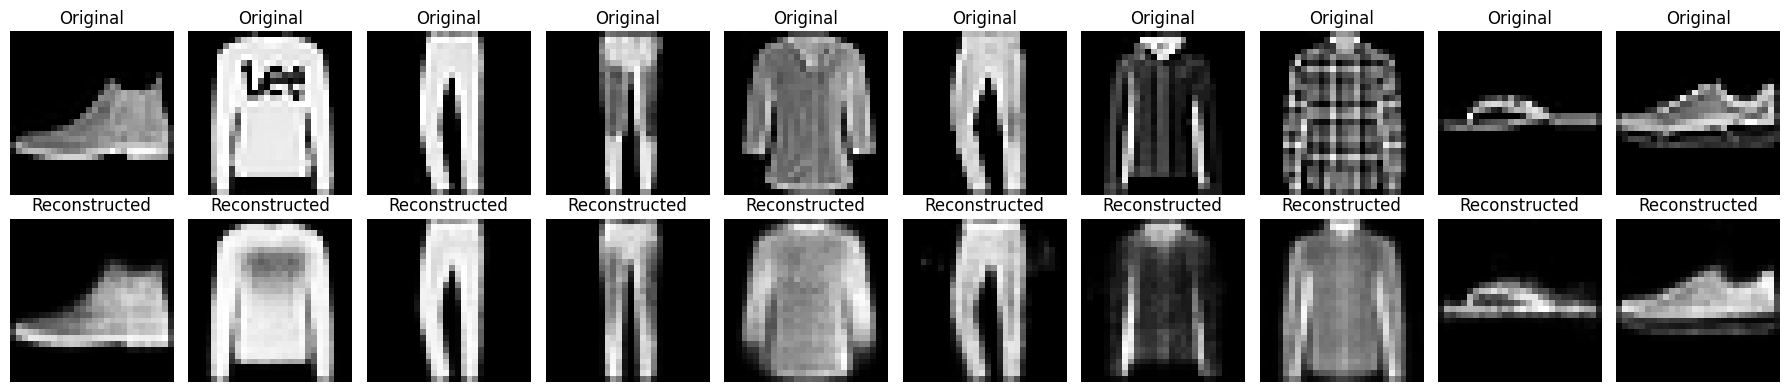

In [8]:
# Visualize Deep Autoencoder reconstructions (test samples)

decoded_deep = deep_ae.predict(x_test_flat)

n = 10
plt.figure(figsize=(18, 4))
for i in range(n):
    # original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # reconstructed
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_deep[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()